Warm up
=======
*Time and dates in python*


**Times series course**  
IMT Mines ALES  
2IA



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Read time series data frame

Download the Air Passenger data.  


In [3]:
# Find the good arguments to read the .csv file
# We load the dataset directly from a public URL to resolve the FileNotFoundError
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'
df = pd.read_csv(url, header = 0, parse_dates = True, names = ['Month', 'Passengers'], index_col = 0)
df

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461


In [4]:
# Slice the dataset using the parsed date index and print the results
subset = df.loc['1949-01-05':'1950-03-17']
print(subset)

            Passengers
Month                 
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
1949-06-01         135
1949-07-01         148
1949-08-01         148
1949-09-01         136
1949-10-01         119
1949-11-01         104
1949-12-01         118
1950-01-01         115
1950-02-01         126
1950-03-01         141


Print the number of air passengers between 1949-01-05 and 1950-03-17.
(tip: since the dates have been parsed as indexes, you can directly use dates as indexes and slice them.)

In [5]:
# Slice and print the data within the specified date range
subset = df.loc['1949-01-05':'1950-03-17']
print(subset)

            Passengers
Month                 
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
1949-06-01         135
1949-07-01         148
1949-08-01         148
1949-09-01         136
1949-10-01         119
1949-11-01         104
1949-12-01         118
1950-01-01         115
1950-02-01         126
1950-03-01         141


## Visualize data

Plot the data with the pandas `plot` function.

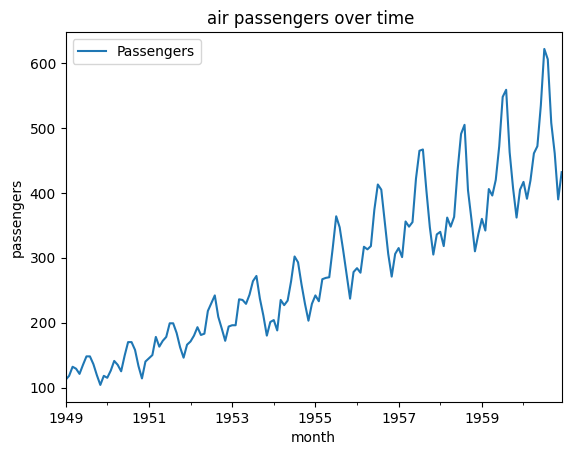

In [8]:
# Plot the passenger data using the pandas plot function
df.plot(title="air passengers over time ", xlabel='month',ylabel='passengers' )
plt.show()

How to get the values of time and passenger number time as numpy arrays?  
Plot these values with `matplotlib`.

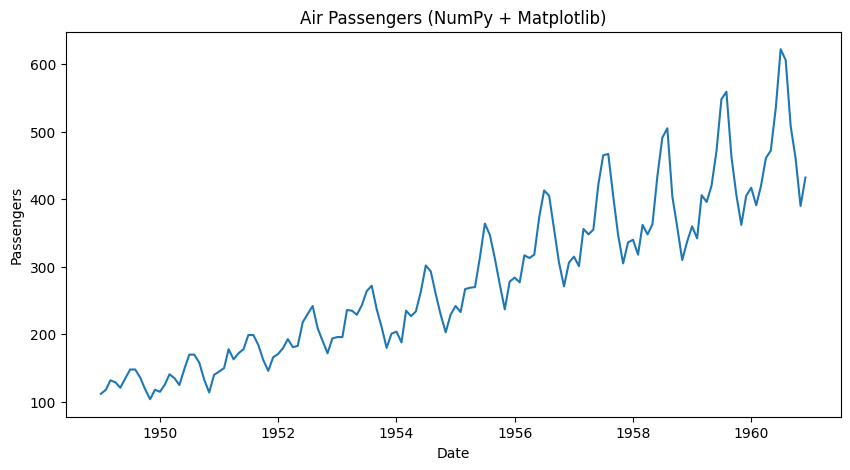

In [9]:
dates_np = df.index.to_numpy()
passengers_np = df['Passengers'].to_numpy()

plt.figure(figsize=(10, 5))
plt.plot(dates_np, passengers_np)
plt.title("Air Passengers (NumPy + Matplotlib)")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.show()

What is the data type of these four kind of values (passengers and dates according to pandas and numpy)?

In [10]:
# Print the data types of dates and passengers in both pandas and numpy formats
print("Pandas Date Index type:", df.index.dtype)
print("Pandas Passengers Column type:", df['Passengers'].dtype)
print("NumPy Dates Array type:", dates_np.dtype)
print("NumPy Passengers Array type:", passengers_np.dtype)

Pandas Date Index type: datetime64[ns]
Pandas Passengers Column type: int64
NumPy Dates Array type: datetime64[ns]
NumPy Passengers Array type: int64


## Manipulate time

### Native Python dates and times
Python's basic objects for working with dates and times reside in the built-in `datetime` module. Along with the third-party `dateutil` module, you can use it to quickly perform a host of useful functionalities on dates and times.

Import the `date` function from the `datetime` module to manually build a date (from year, month and day number). Print its type.

In [11]:
from datetime import date

# Manually build a date (e.g., November 28, 2024)
my_date = date(2024, 11, 28)

print("Built Date:", my_date)
print("Type of Built Date:", type(my_date))

Built Date: 2024-11-28
Type of Built Date: <class 'datetime.date'>


Import the `parser` from the `dateutil` module and use the `parse` function with the following date: "28th of November, 2024".

In [12]:
from dateutil import parser

my_date= parser.parse("28th of November, 2024")
print(my_date)

2024-11-28 00:00:00


### Typed arrays of times with numpy
The weaknesses of Python's `datetime` format inspired the NumPy team to add a set of native time series data type to NumPy. The `datetime64` dtype encodes dates as 64-bit integers, and thus allows arrays of dates to be represented very compactly. The datetime64 requires a very specific input format.

In [13]:
# With numpy and datetime

from datetime import timedelta, datetime

date = np.array('2015-07-04', dtype=np.datetime64)
print("date: ", date)


t = np.arange(datetime(1985,7,1), datetime(2015,7,1), timedelta(days=1))
print("t: ", t)

# Conversion from numpy datetime64 to python datetime
print("Conversion to datetime: ", t.astype(datetime))


date:  2015-07-04
t:  ['1985-07-01T00:00:00.000000' '1985-07-02T00:00:00.000000'
 '1985-07-03T00:00:00.000000' ... '2015-06-28T00:00:00.000000'
 '2015-06-29T00:00:00.000000' '2015-06-30T00:00:00.000000']
Conversion to datetime:  [datetime.datetime(1985, 7, 1, 0, 0) datetime.datetime(1985, 7, 2, 0, 0)
 datetime.datetime(1985, 7, 3, 0, 0) ...
 datetime.datetime(2015, 6, 28, 0, 0) datetime.datetime(2015, 6, 29, 0, 0)
 datetime.datetime(2015, 6, 30, 0, 0)]


In [14]:
# force a nanosecond-based time
np.datetime64('2015-07-04 12:59:59.50', 'ns')

np.datetime64('2015-07-04T12:59:59.500000000')

Check with `numpy` if today is a business days

In [15]:
today_date = np.datetime64('today') # today's date

print("Today is a business day: ", np.is_busday(today_date))

Today is a business day:  True


### Dates and times in pandas: best of both worlds
Pandas builds upon all the tools just discussed to provide a `Timestamp` object, which combines the ease-of-use of `datetime` and `dateutil` with the efficient storage and vectorized interface of `numpy.datetime64`. From a group of these `Timestamp` objects, Pandas can construct a `DatetimeIndex` that can be used to index data in a Series or `DataFrame`.

In [16]:
date = pd.to_datetime("4th of July, 2015")
print(date)
print(type(date))


2015-07-04 00:00:00
<class 'pandas._libs.tslibs.timestamps.Timestamp'>


Is '7/1/2016' in January or July?

In [17]:
# Check if '7/1/2016' is parsed as January or July
date_parsed = pd.to_datetime('7/1/2016')
print("Parsed Date:", date_parsed)
print("Month:", date_parsed.strftime('%B'))

Parsed Date: 2016-07-01 00:00:00
Month: July


Which of these formats DON'T work?
- '2016 Jul 1'
- '7/1/2016'
- '1/7/2016'
- 'July 1, 2016'
- '2016-07-01'
- '2016/07/01'


In [18]:
formats = [
    '2016 Jul 1',
    '7/1/2016',
    '1/7/2016',
    'July 1, 2016',
    '2016-07-01',
    '2016/07/01'
]

for fmt in formats:
    try:
        parsed = pd.to_datetime(fmt)
        print(f"✅ '{fmt}' works -> {parsed}")
    except Exception as e:
        print(f"❌ '{fmt}' FAILS -> {e}")

✅ '2016 Jul 1' works -> 2016-07-01 00:00:00
✅ '7/1/2016' works -> 2016-07-01 00:00:00
✅ '1/7/2016' works -> 2016-01-07 00:00:00
✅ 'July 1, 2016' works -> 2016-07-01 00:00:00
✅ '2016-07-01' works -> 2016-07-01 00:00:00
✅ '2016/07/01' works -> 2016-07-01 00:00:00


For time Periods (time spans), Pandas provides the Period type. This encodes a fixed-frequency interval based on numpy.datetime64. The associated index structure is PeriodIndex.

In [19]:
# Range of dates

rng = pd.date_range('2016 Jul 1', periods = 10, freq = 'D')
rng

DatetimeIndex(['2016-07-01', '2016-07-02', '2016-07-03', '2016-07-04',
               '2016-07-05', '2016-07-06', '2016-07-07', '2016-07-08',
               '2016-07-09', '2016-07-10'],
              dtype='datetime64[ns]', freq='D')

In [20]:
# With frequency

pd.timedelta_range(0, periods=9, freq="2H30T")

/tmp/ipykernel_429/2918652638.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  pd.timedelta_range(0, periods=9, freq="2H30T")
/tmp/ipykernel_429/2918652638.py:3: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  pd.timedelta_range(0, periods=9, freq="2H30T")


TimedeltaIndex(['0 days 00:00:00', '0 days 02:30:00', '0 days 05:00:00',
                '0 days 07:30:00', '0 days 10:00:00', '0 days 12:30:00',
                '0 days 15:00:00', '0 days 17:30:00', '0 days 20:00:00'],
               dtype='timedelta64[ns]', freq='150min')

In [21]:
# Use business days

from pandas.tseries.offsets import BDay
pd.date_range('2015-07-01', periods=5, freq=BDay())


DatetimeIndex(['2015-07-01', '2015-07-02', '2015-07-03', '2015-07-06',
               '2015-07-07'],
              dtype='datetime64[ns]', freq='B')

## Resampling, Shifting, and Windowing

For the following cells, you will use `Yahoo! Finance` that provide a set of time series data.     
You can install it with the following command:   
`pip install yfinance`

In [22]:
import yfinance as yf

goog = yf.download('GOOG', start='2004-01-01', end='2024-09-01')
goog.head()


/tmp/ipykernel_429/1411979671.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  goog = yf.download('GOOG', start='2004-01-01', end='2024-09-01')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG
Date,,,,,
2004-08-19,2.475684,2.567467,2.367617,2.467295,897427216
2004-08-20,2.672328,2.691325,2.479632,2.492215,458857488
2004-08-23,2.699221,2.799886,2.690586,2.732529,366857939
2004-08-24,2.587453,2.753501,2.555378,2.744619,306396159
2004-08-25,2.615332,2.664679,2.563026,2.589672,184645512


<Axes: xlabel='Date'>

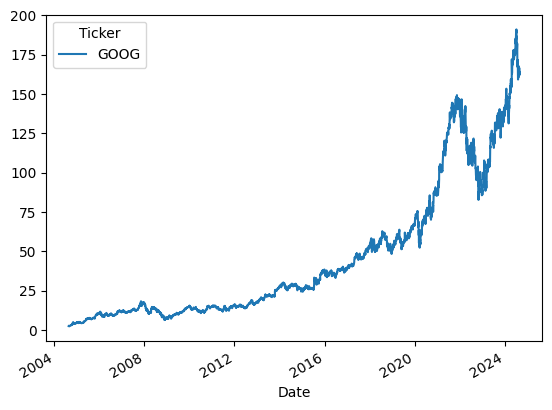

In [23]:
# Closing price of the google stock
goog['Close'].plot()

What is the overall trend in Apple stock over the 2019-2020 period? How would you explain the main downward?

/tmp/ipykernel_429/2243737400.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  aapl = yf.download('AAPL', start='2019-01-01', end='2020-12-31')
[*********************100%***********************]  1 of 1 completed


<Figure size 1000x500 with 0 Axes>

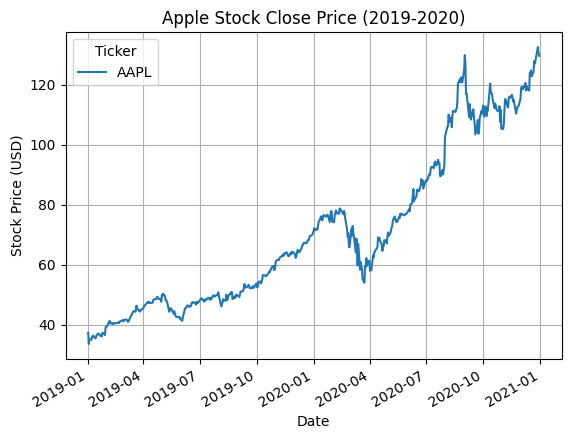

Overall Trend:
Apple's stock experienced a strong overall upward (bullish) trend throughout 2019 and 2020, driven by solid financial performances, product launches, and growth in services.

Explanation of the main downward:
The most significant downward movement occurred in February and March 2020. This sharp drop was caused by the onset of the global COVID-19 pandemic, which triggered widespread economic uncertainty, supply chain disruptions, and a broader stock market crash.


In [24]:
import yfinance as yf
import matplotlib.pyplot as plt

# Download Apple stock data for the 2019-2020 period
aapl = yf.download('AAPL', start='2019-01-01', end='2020-12-31')

# Plotting the Close price
plt.figure(figsize=(10, 5))
aapl['Close'].plot()
plt.title("Apple Stock Close Price (2019-2020)")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")
plt.grid(True)
plt.show()

# Explanation
print("""Overall Trend:
Apple's stock experienced a strong overall upward (bullish) trend throughout 2019 and 2020, driven by solid financial performances, product launches, and growth in services.

Explanation of the main downward:
The most significant downward movement occurred in February and March 2020. This sharp drop was caused by the onset of the global COVID-19 pandemic, which triggered widespread economic uncertainty, supply chain disruptions, and a broader stock market crash.""")

/tmp/ipykernel_429/4080272271.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  aapl = yf.download('AAPL', start='2019-01-01', end='2020-12-31')
[*********************100%***********************]  1 of 1 completed


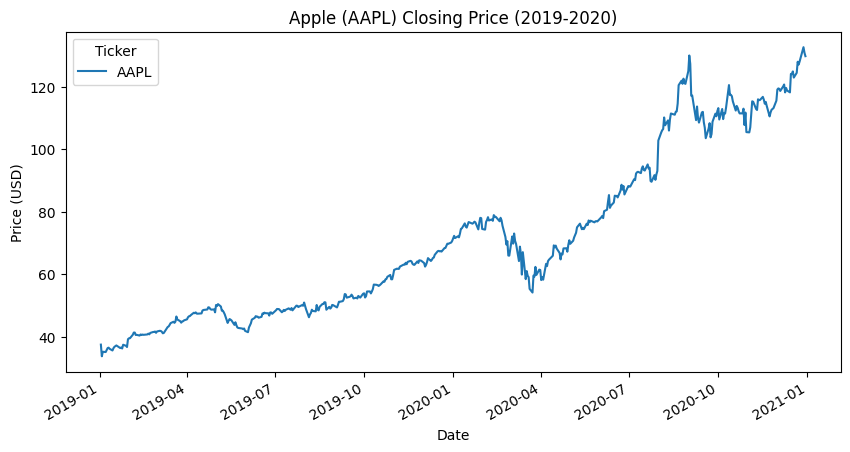

In [25]:
aapl = yf.download('AAPL', start='2019-01-01', end='2020-12-31')
aapl['Close'].plot(figsize=(10, 5), title="Apple (AAPL) Closing Price (2019-2020)")
plt.ylabel("Price (USD)")
plt.show()

One common need for time series data is **resampling** at a higher or lower frequency. This can be done using the `resample()` method, or the much simpler `asfreq()` method. The primary difference between the two is that `resample()` is fundamentally a data aggregation, while `asfreq()` is fundamentally a data selection.

/tmp/ipykernel_429/2692758753.py:6: FutureWarning: 'BA' is deprecated and will be removed in a future version, please use 'BYE' instead.
  goog.resample('BA').mean().plot(style=':')
/tmp/ipykernel_429/2692758753.py:8: FutureWarning: 'BA' is deprecated and will be removed in a future version, please use 'BYE' instead.
  goog.asfreq('BA').plot(style='--');


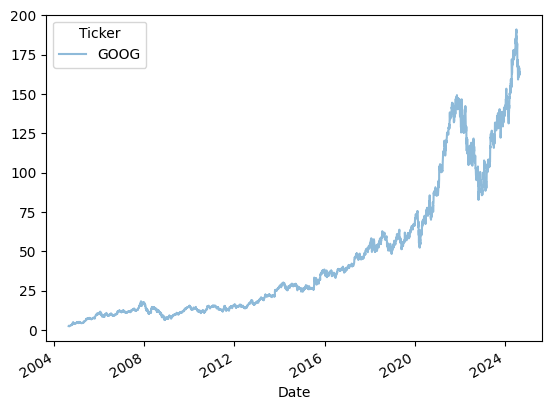

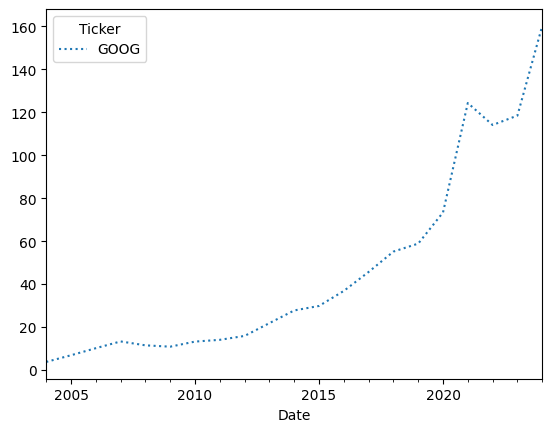

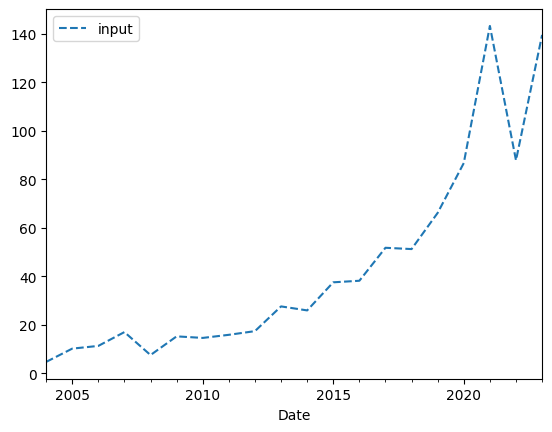

In [26]:
# Resample the data at the end of business year (BA):

goog = goog['Close']

goog.plot(alpha=0.5, style='-')
goog.resample('BA').mean().plot(style=':')

goog.asfreq('BA').plot(style='--');

plt.legend(['input', 'resample', 'asfreq'], loc='upper left');





Verify that at each point, `resample` reports the average of the previous year, while `asfreq` reports the value at the end of the year.

## Data imputation

For up-sampling, `resample()` and `asfreq()` are largely equivalent, though `resample` has many more options available. In the case of missing values, the default for both methods is to leave the up-sampled points empty, that is, filled with NA values.

`asfreq()` accepts a method argument to specify how values are imputed. Here, we will `resample` the business day data at a daily frequency (i.e., including weekends):

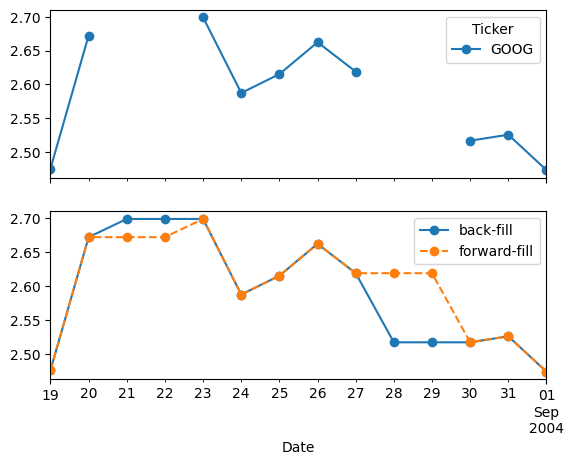

In [27]:
fig, ax = plt.subplots(2, sharex=True)
data = goog.iloc[:10]

data.asfreq('D').plot(ax=ax[0], marker='o')

data.asfreq('D', method='bfill').plot(ax=ax[1], style='-o')
data.asfreq('D', method='ffill').plot(ax=ax[1], style='--o')
ax[1].legend(["back-fill", "forward-fill"]);

### Time-shifts

Another common time series-specific operation is shifting of data in time, using the `shift()` method in Pandas.

Here we will `shift()` by 900 days:

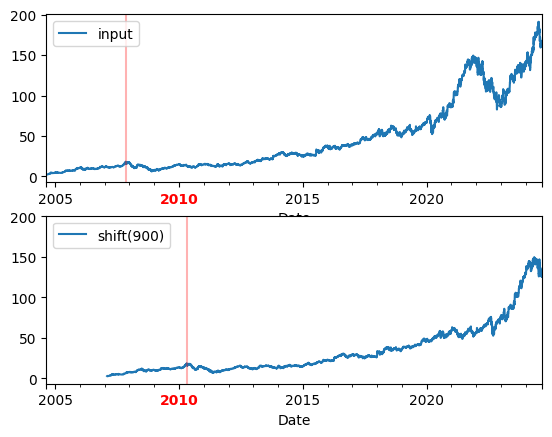

In [28]:
fig, ax = plt.subplots(2, sharey=True)

# apply a frequency to the data
goog = goog.asfreq('D', method='pad')

goog.plot(ax=ax[0])
goog.shift(900).plot(ax=ax[1])

# legends and annotations
local_max = pd.to_datetime('2007-11-05')
offset = pd.Timedelta(900, 'D')

ax[0].legend(['input'], loc=2)
ax[0].get_xticklabels()[2].set(weight='heavy', color='red')
ax[0].axvline(local_max, alpha=0.3, color='red')

ax[1].legend(['shift(900)'], loc=2)
ax[1].get_xticklabels()[2].set(weight='heavy', color='red')
ax[1].axvline(local_max + offset, alpha=0.3, color='red')


### Rolling windows

Rolling statistics are a third type of time series-specific operation implemented by Pandas. These can be accomplished via the `rolling()` attribute of Series and DataFrame objects.

This rolling view makes available a number of aggregation operations by default.

For example, here is the one-year centered rolling mean and standard deviation of the Google stock prices:

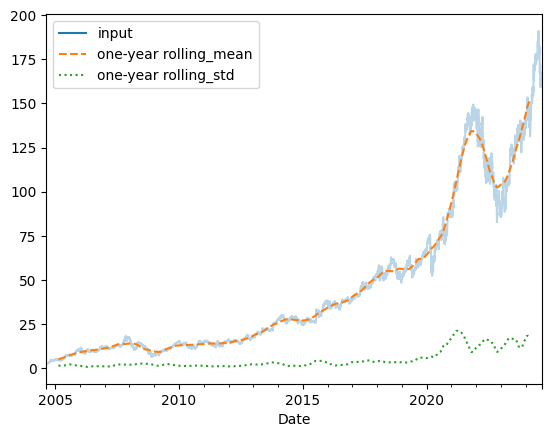

In [30]:
rolling = goog.rolling(365, center=True)

data = pd.DataFrame({'input': goog, 'one-year rolling_mean': rolling.mean(), 'one-year rolling_std': rolling.std()})
ax = data.plot(style=['-', '--', ':'])
ax.lines[0].set_alpha(0.3)